# Chapitre 1 - Cours 2 : entrepôts, lacs et données dérivées

Le cours 1 a montré pourquoi l'analytique doit vivre ailleurs que dans les bases
opérationnelles. Ce notebook suit le chemin des données vers ce « ailleurs » : l'entrepôt
de données, alimenté par ETL ou ELT, puis le lac de données et ses successeurs. Il se
termine par une distinction qui servira dans tout le livre : **système de référence**
contre **données dérivées**. Sections couvertes : *Data Warehousing* (avec *From data
warehouse to data lake* et *Beyond the data lake*) et *Systems of Record and Derived
Data*.

**Plan.**

1. Les silos de données et l'entrepôt : un ETL complet, de trois bases sources à un
   schéma en étoile.
2. ETL ou ELT, et ce que l'instantané périodique ne voit pas.
3. HTAP et spécialisation : pourquoi un seul système ne fait pas tout.
4. Du data warehouse au data lake : fichiers bruts, schéma à la lecture, ingénierie des
   caractéristiques.
5. Au-delà du lac : flux d'événements et « reverse ETL ».
6. Systèmes de référence et données dérivées : reconstruire, propager, tracer.

In [1]:
import json
import re
import sqlite3
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from ddia import architecture as ar
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Les silos de données et l'entrepôt (section *Data Warehousing*)

**Le problème.** Une grande organisation a des dizaines, voire des centaines de systèmes
OLTP : site marchand, caisses des magasins, stocks, logistique, fournisseurs, paie.
Chacun a son équipe, son schéma, ses conventions, et vit à peu près indépendamment des
autres. Interroger directement ces systèmes pour l'analytique pose quatre problèmes :
les données utiles sont **dispersées** (on parle de **silos**) et impossibles à combiner
en une requête ; les schémas OLTP conviennent mal à l'analyse ; les requêtes analytiques
**pénalisent** les utilisateurs (cours 1) ; et les bases OLTP sont souvent sur un réseau
auquel les analystes n'ont pas accès, pour des raisons de sécurité.

D'où l'**entrepôt de données** (« data warehouse »), apparu à la fin des années 1980 : une
base séparée, en lecture seule pour les analystes, qui contient une copie des données de
tous les systèmes OLTP. Les données y arrivent par **ETL** (*extract, transform, load*) :
extraites des bases sources (export périodique ou flux continu de modifications),
transformées en un schéma propice à l'analyse, nettoyées, puis chargées.

**Trois silos.** Construisons trois bases sources indépendantes, chacune avec ses
conventions, comme dans la vraie vie :

- le **site web** enregistre des commandes avec l'e-mail du client et des montants **en
  centimes** ;
- les **caisses** enregistrent des tickets avec le numéro de carte de fidélité, des
  montants **en euros** et des dates au format **jj/mm/aaaa** ;
- le **CRM** (gestion de la relation client) relie e-mails, cartes et segments de
  clientèle, avec quelques e-mails mal saisis (majuscules, espaces).

In [2]:
N_CUST = 300
segments = rng.choice(["étudiant", "famille", "senior", "professionnel"], N_CUST, p=[0.2, 0.4, 0.25, 0.15])
emails = [f"client{i}@exemple.fr" for i in range(N_CUST)]
cards = [f"F{100000 + 7 * i}" for i in range(N_CUST)]

crm = sqlite3.connect(":memory:")
crm.execute("CREATE TABLE contacts (contact_id INTEGER PRIMARY KEY, email TEXT, loyalty_card TEXT, segment TEXT)")
crm.executemany("INSERT INTO contacts VALUES (?, ?, ?, ?)",
                ((i, (f"  {e.upper()} " if i % 17 == 0 else e), cards[i], segments[i])
                 for i, e in enumerate(emails)))

web = sqlite3.connect(":memory:")
web.execute("CREATE TABLE orders (order_id INTEGER PRIMARY KEY, email TEXT, total_cents INTEGER, created_at TEXT)")
n_web = 3000
wc = rng.integers(0, N_CUST, n_web)
web.executemany("INSERT INTO orders VALUES (?, ?, ?, ?)",
                ((i, emails[c], int(rng.lognormal(8.3, 0.5)), f"2025-{1 + i * 3 // n_web:02d}-{1 + i % 28:02d}")
                 for i, c in enumerate(wc)))
web.execute("INSERT INTO orders VALUES (99999, 'inconnu@nulle.part', 1500, '2025-02-10')")   # client absent du CRM

pos = sqlite3.connect(":memory:")
pos.execute("CREATE TABLE tickets (ticket_no TEXT PRIMARY KEY, card TEXT, amount_eur REAL, date_fr TEXT, store TEXT)")
n_pos = 5000
pc = rng.integers(0, N_CUST, n_pos)
pos.executemany("INSERT INTO tickets VALUES (?, ?, ?, ?, ?)",
                ((f"T{i:06d}", cards[c], round(float(rng.lognormal(3.4, 0.6)), 2),
                  f"{1 + i % 28:02d}/{1 + i * 3 // n_pos:02d}/2025", f"magasin {i % 5}")
                 for i, c in enumerate(pc)))
pos.execute("INSERT INTO tickets VALUES ('T999999', NULL, 12.5, '03/02/2025', 'magasin 1')")  # client anonyme

pd.DataFrame({"source": ["CRM", "site web", "caisses"],
              "table": ["contacts", "orders", "tickets"],
              "exemple de ligne": [str(crm.execute("SELECT * FROM contacts WHERE contact_id = 17").fetchone()),
                                   str(web.execute("SELECT * FROM orders LIMIT 1").fetchone()),
                                   str(pos.execute("SELECT * FROM tickets LIMIT 1").fetchone())]})

,source,table,exemple de ligne
0,CRM,contacts,"(17, ' CLIENT17@EXEMPLE.FR ', 'F100119', 'fam..."
1,site web,orders,"(0, 'client175@exemple.fr', 2128, '2025-01-01')"
2,caisses,tickets,"('T000000', 'F101253', 28.47, '01/01/2025', 'm..."


La question d'un analyste, « quel chiffre d'affaires par segment de clientèle et par
canal, chaque mois ? », est **impossible** à poser en une requête : il faudrait joindre
trois bases différentes, sur des clés différentes (e-mail d'un côté, carte de l'autre),
avec des unités et des formats de date différents. C'est le rôle de l'ETL.

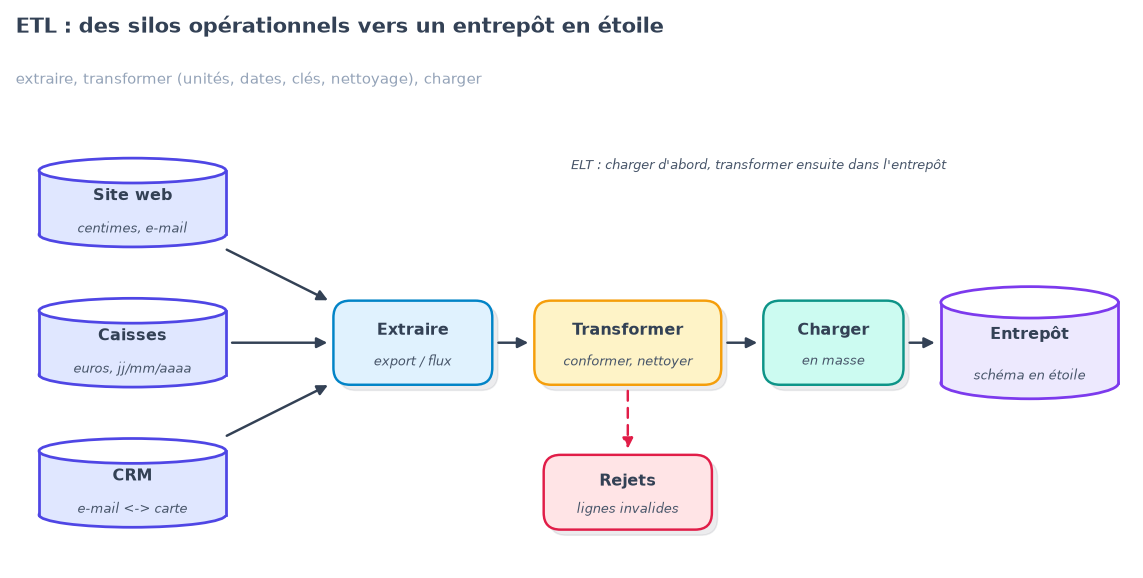

In [3]:
d = Diagram(12, 5.0, title="ETL : des silos opérationnels vers un entrepôt en étoile",
            subtitle="extraire, transformer (unités, dates, clés, nettoyage), charger")
d.box("web", 1.3, 3.9, "Site web", sub="centimes, e-mail", color=INDIGO, kind="db", w=2.0, h=0.95)
d.box("pos", 1.3, 2.4, "Caisses", sub="euros, jj/mm/aaaa", color=INDIGO, kind="db", w=2.0, h=0.95)
d.box("crm", 1.3, 0.9, "CRM", sub="e-mail <-> carte", color=INDIGO, kind="db", w=2.0, h=0.95)
d.box("x", 4.3, 2.4, "Extraire", sub="export / flux", color=SKY, w=1.7)
d.box("t", 6.6, 2.4, "Transformer", sub="conformer, nettoyer", color=AMBER, w=2.0)
d.box("l", 8.8, 2.4, "Charger", sub="en masse", color=TEAL, w=1.5)
d.box("dw", 10.9, 2.4, "Entrepôt", sub="schéma en étoile", color=VIOLET, kind="db", w=1.9, h=1.2)
for s in ("web", "pos", "crm"):
    d.arrow(s, "x")
d.arrow("x", "t"); d.arrow("t", "l"); d.arrow("l", "dw")
d.box("rej", 6.6, 0.8, "Rejets", sub="lignes invalides", color=ROSE, w=1.8, h=0.8)
d.arrow("t", "rej", style="dashed", color=ROSE)
d.note(8.0, 4.3, "ELT : charger d'abord, transformer ensuite dans l'entrepôt", fontsize=8.5)
d.show()

L'entrepôt adopte un **schéma en étoile** (détaillé au chapitre 3) : une
**table de faits** (une ligne par vente, tous canaux confondus) entourée de **tables de
dimensions** (client, date, canal). Écrivons l'ETL en Python : l'étape de transformation
est celle où se concentre le travail, et les **rejets** y sont comptés plutôt que
silencieusement ignorés.

In [4]:
def extract():
    return {"contacts": crm.execute("SELECT * FROM contacts").fetchall(),
            "orders": web.execute("SELECT * FROM orders").fetchall(),
            "tickets": pos.execute("SELECT * FROM tickets").fetchall()}


def transform(raw):
    rejects = []
    norm = lambda e: e.strip().lower()                                  # nettoyage des e-mails
    dim_customer = [(cid, segment) for cid, _, _, segment in raw["contacts"]]
    by_email = {norm(e): cid for cid, e, _, _ in raw["contacts"]}        # conformer les clés
    by_card = {card: cid for cid, _, card, _ in raw["contacts"]}
    facts = []
    for oid, email, cents, created in raw["orders"]:
        cid = by_email.get(norm(email))
        if cid is None:
            rejects.append(("site web", oid, "e-mail inconnu du CRM")); continue
        facts.append((f"W{oid}", cid, "web", created, cents / 100))           # centimes -> euros
    for tno, card, eur, date_fr in (r[:4] for r in raw["tickets"]):
        cid = by_card.get(card)
        if cid is None:
            rejects.append(("caisses", tno, "ticket sans carte de fidélité")); continue
        dd, mm, yyyy = date_fr.split("/")
        facts.append((tno, cid, "magasin", f"{yyyy}-{mm}-{dd}", eur))         # jj/mm/aaaa -> ISO
    return dim_customer, facts, rejects


def load(dw, dim_customer, facts):
    dw.executescript("""
    CREATE TABLE dim_customer (customer_key INTEGER PRIMARY KEY, segment TEXT);
    CREATE TABLE fact_sales (sale_id TEXT PRIMARY KEY, customer_key INTEGER, channel TEXT,
                             day TEXT, amount_eur REAL);
    """)
    dw.executemany("INSERT INTO dim_customer VALUES (?, ?)", dim_customer)
    dw.executemany("INSERT INTO fact_sales VALUES (?, ?, ?, ?, ?)", facts)
    dw.commit()


dw = sqlite3.connect(":memory:")
dim_customer, facts, rejects = transform(extract())
load(dw, dim_customer, facts)
print(f"{fmt(len(facts))} ventes chargées, {len(rejects)} rejet(s) :")
for r in rejects:
    print("  ", r)

8 000 ventes chargées, 2 rejet(s) :
   ('site web', 99999, 'e-mail inconnu du CRM')
   ('caisses', 'T999999', 'ticket sans carte de fidélité')


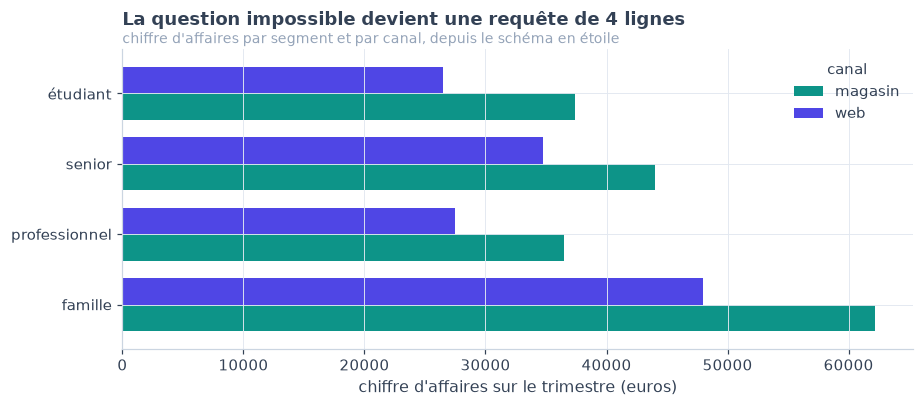

In [5]:
report = pd.read_sql("""
SELECT substr(f.day, 1, 7) AS mois, c.segment, f.channel AS canal, ROUND(SUM(f.amount_eur)) AS ca_eur
  FROM fact_sales f JOIN dim_customer c USING (customer_key)
 GROUP BY mois, c.segment, canal""", dw)
pivot = report.pivot_table(index=["segment"], columns=["canal"], values="ca_eur", aggfunc="sum")
fig, ax = plt.subplots(figsize=(8.5, 3.8))
pivot.plot.barh(ax=ax, color=[TEAL, INDIGO], width=0.75)
ax.set_xlabel("chiffre d'affaires sur le trimestre (euros)")
ax.set_ylabel("")
ax.set_title("La question impossible devient une requête de 4 lignes")
subtitle(ax, "chiffre d'affaires par segment et par canal, depuis le schéma en étoile")
ax.legend(title="canal"); plt.tight_layout(); plt.show()

Une fois les données **conformées** (mêmes clés, mêmes unités, mêmes formats), la
question se pose en une seule requête SQL. Les deux rejets sont instructifs : une
commande d'un client absent du CRM et un ticket anonyme. Une bonne chaîne ETL ne les
jette pas en silence ; elle les compte et les signale, sinon les totaux de l'entrepôt
divergent sans explication de ceux des systèmes sources.

> **À retenir.** L'entrepôt réunit, dans un schéma pensé pour l'analyse, une copie en
> lecture seule des données de tous les systèmes OLTP. L'essentiel du travail est la
> transformation : conformer les clés, les unités et les formats, nettoyer, rendre compte
> des rejets.

## 2. ETL ou ELT, et ce que l'instantané ne voit pas (section *Data Warehousing*)

**ELT.** On peut aussi inverser les deux dernières étapes : **charger** les données brutes
telles quelles dans l'entrepôt, puis les **transformer** en SQL, dans l'entrepôt lui-même.
Intérêt principal : les données brutes restent disponibles. Si l'on découvre une erreur de
transformation, on corrige la requête et on recalcule, sans retourner extraire les
sources (qui ont peut-être changé ou effacé l'historique entre-temps).

Démontrons-le avec une erreur classique : la première version de la transformation
oublie de convertir les centimes du site web.

In [6]:
elt = sqlite3.connect(":memory:")
raw = extract()
elt.execute("CREATE TABLE raw_orders (order_id, email, total_cents, created_at)")
elt.execute("CREATE TABLE raw_tickets (ticket_no, card, amount_eur, date_fr, store)")
elt.execute("CREATE TABLE raw_contacts (contact_id, email, loyalty_card, segment)")
elt.executemany("INSERT INTO raw_orders VALUES (?, ?, ?, ?)", raw["orders"])
elt.executemany("INSERT INTO raw_tickets VALUES (?, ?, ?, ?, ?)", raw["tickets"])
elt.executemany("INSERT INTO raw_contacts VALUES (?, ?, ?, ?)", raw["contacts"])

TRANSFORM_V1 = """
DROP TABLE IF EXISTS sales;
CREATE TABLE sales AS
SELECT 'web' AS channel, c.segment, o.total_cents AS amount_eur           -- erreur : centimes !
  FROM raw_orders o JOIN raw_contacts c ON lower(trim(c.email)) = o.email
UNION ALL
SELECT 'magasin', c.segment, t.amount_eur
  FROM raw_tickets t JOIN raw_contacts c ON c.loyalty_card = t.card;
"""
TRANSFORM_V2 = TRANSFORM_V1.replace("o.total_cents AS amount_eur           -- erreur : centimes !",
                                    "o.total_cents / 100.0 AS amount_eur")
res = {}
for name, sql in [("v1 (erronée)", TRANSFORM_V1), ("v2 (corrigée)", TRANSFORM_V2)]:
    t0 = time.perf_counter()
    elt.executescript(sql)
    res[name] = dict(elt.execute("SELECT channel, ROUND(SUM(amount_eur)) FROM sales GROUP BY channel").fetchall())
    res[name]["recalcul (ms)"] = (time.perf_counter() - t0) * 1e3
pd.DataFrame(res).T

,magasin,web,recalcul (ms)
v1 (erronée),180078.0,1.368e+07,3.220
v2 (corrigée),180078.0,1.368e+05,3.249


Avec la version erronée, le site web semble rapporter cent fois plus que les magasins ;
la correction se résume à modifier la requête et à la relancer sur les données brutes
déjà présentes, en quelques millisecondes ici. Avec un ETL pur, il aurait fallu
ré-extraire les sources. C'est l'une des raisons du succès de l'ELT, à côté de la
puissance des entrepôts modernes, capables d'exécuter eux-mêmes ces transformations.

**Les sources SaaS.** Une partie des données vient souvent de logiciels externes (CRM,
e-mailing, paiement) dont on n'a pas la base, seulement l'**API** du fournisseur. Des
services de connecteurs spécialisés (Fivetran, Singer, Airbyte) se chargent de
l'extraction ; les rapatrier dans son entrepôt permet des analyses impossibles via l'API
seule.

**Ce que l'instantané ne voit pas.** Le tableau 1-1 du livre l'indique : une base OLTP
représente l'**état courant**, un système analytique l'**historique**. Si l'extraction
est un export périodique (un instantané par jour, par exemple), tous les états
intermédiaires entre deux exports sont perdus. Pour un enregistrement modifié selon un
processus de Poisson de taux $\lambda$, un instantané toutes les $T$ ne capture qu'une
fraction

$$f(\lambda T) = \frac{1 - e^{-\lambda T}}{\lambda T}$$

des versions (fonction `ar.snapshot_capture_fraction`) : chaque période voit au plus
une version, alors qu'il y en a $\lambda T$ en moyenne. Vérifions par simulation, puis
visualisons une trajectoire de prix.

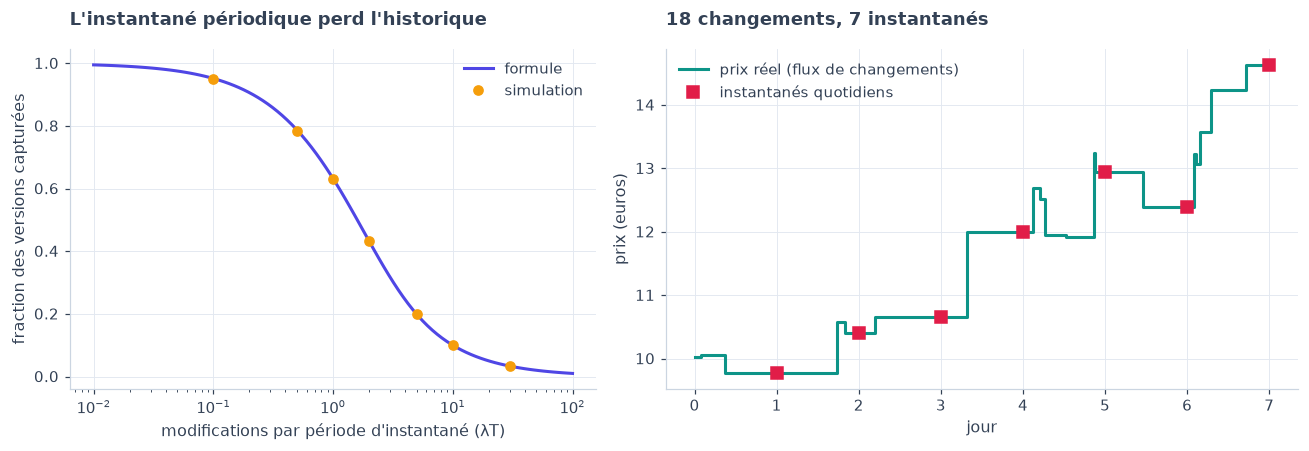

In [7]:
x = np.logspace(-2, 2, 100)
sim_pts = []
for lt in [0.1, 0.5, 1, 2, 5, 10, 30]:
    t = np.cumsum(rng.exponential(1 / lt, 50_000))            # T = 1
    sim_pts.append((lt, np.unique(np.floor(t)).size / t.size))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
ax.semilogx(x, [ar.snapshot_capture_fraction(v, 1) for v in x], color=INDIGO, label="formule")
ax.plot(*zip(*sim_pts), "o", color=AMBER, label="simulation")
ax.set_xlabel("modifications par période d'instantané (λT)"); ax.set_ylabel("fraction des versions capturées")
ax.set_title("L'instantané périodique perd l'historique"); ax.legend()
ax = axes[1]
ch = np.sort(rng.uniform(0, 7, 18))                          # 18 changements de prix en 7 jours
prices = 10 + np.cumsum(rng.normal(0, 0.6, ch.size + 1))
tt = np.concatenate([[0], ch, [7]])
ax.step(tt, np.concatenate([prices, [prices[-1]]]), where="post", color=TEAL, label="prix réel (flux de changements)")
snap_t = np.arange(1, 8)
snap_v = [prices[np.searchsorted(ch, s, side="right")] for s in snap_t]
ax.plot(snap_t, snap_v, "s", color=ROSE, ms=8, label="instantanés quotidiens")
ax.set_xlabel("jour"); ax.set_ylabel("prix (euros)")
ax.set_title(f"{ch.size} changements, {len(snap_t)} instantanés"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

Dès qu'un enregistrement change plus souvent qu'on ne l'exporte, l'entrepôt ne voit
qu'une petite fraction de son histoire : à dix changements par période, il en manque
90 %. D'où l'intérêt de l'extraction par **flux continu de modifications** (capture de
changements, « change data capture », chapitre 12), qui transmet chaque version.

> **À retenir.** ETL transforme avant de charger ; ELT charge les données brutes et les
> transforme dans l'entrepôt, ce qui permet de corriger et de recalculer. Un export
> périodique ne voit que l'état courant à chaque export ; seul un flux de modifications
> restitue tout l'historique.

## 3. HTAP et spécialisation (section *Data Warehousing*)

Certains systèmes promettent de tout faire : le **HTAP** (*hybrid transactional/analytical
processing*) vise l'OLTP et l'analytique dans un même système, sans ETL. Le livre
tempère : beaucoup de systèmes HTAP sont en interne un moteur OLTP couplé à un moteur
analytique, derrière une interface commune ; et comme une organisation garde des
dizaines de bases opérationnelles mais veut **un** entrepôt pour croiser leurs données, le
HTAP ne remplace pas l'entrepôt. Il sert quand **une même application** a besoin des
deux, par exemple la détection de fraude (lire et modifier un compte, tout en agrégeant
son historique).

Pourquoi deux moteurs plutôt qu'un ? Parce que les organisations physiques qui
avantagent l'un pénalisent l'autre. Expérience minimale : un million de ventes rangées
**par ligne** (un dictionnaire de tuples indexé par identifiant, comme une table OLTP) ou
**par colonne** (un tableau numpy par attribut, comme un entrepôt moderne). On mesure une
lecture ponctuelle et une somme sur toute la table.

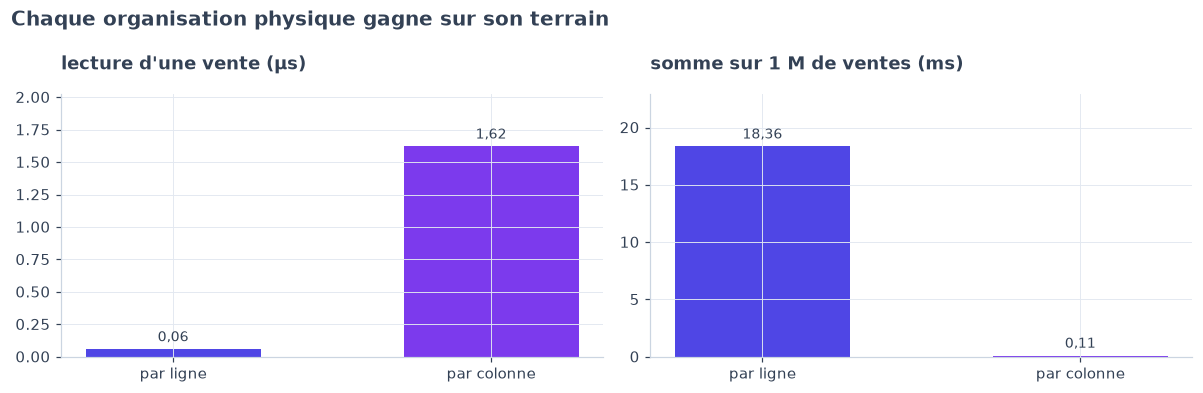

,par ligne (dict de tuples),par colonne (tableaux numpy)
lecture d'une vente (µs),0.059,1.622
somme sur 1 M de ventes (ms),18.355,0.109


In [8]:
N = 1_000_000
ids = np.arange(N)
amount = rng.lognormal(3, 0.7, N)
store = rng.integers(0, 20, N)
rows_store = {int(i): (int(i), int(s), float(a)) for i, s, a in zip(ids, store, amount)}
col_store = {"id": ids, "store": store, "amount": amount}


def bench(fn, repeat=5):
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter(); fn(); best = min(best, time.perf_counter() - t0)
    return best


keys = rng.integers(0, N, 1000)
t_point_row = bench(lambda: [rows_store[int(k)] for k in keys]) / keys.size
t_point_col = bench(lambda: [(k, store[np.searchsorted(ids, k)], amount[np.searchsorted(ids, k)]) for k in keys]) / keys.size
t_scan_row = bench(lambda: sum(r[2] for r in rows_store.values()), repeat=2)
t_scan_col = bench(lambda: amount.sum())
perf = pd.DataFrame({"par ligne (dict de tuples)": [t_point_row * 1e6, t_scan_row * 1e3],
                     "par colonne (tableaux numpy)": [t_point_col * 1e6, t_scan_col * 1e3]},
                    index=["lecture d'une vente (µs)", "somme sur 1 M de ventes (ms)"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (lab, row) in zip(axes, perf.iterrows()):
    b = ax.bar(["par ligne", "par colonne"], row.values, color=[INDIGO, VIOLET], width=0.55)
    ax.bar_label(b, labels=[f"{v:.2f}".replace(".", ",") for v in row.values], fontsize=9, padding=3)
    ax.set_title(lab); ax.set_ylim(0, row.max() * 1.25)
fig.suptitle("Chaque organisation physique gagne sur son terrain", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()
perf

La disposition par ligne retrouve une vente une vingtaine de fois plus vite (un accès de
dictionnaire contre deux recherches dichotomiques et la reconstitution de la ligne) ; la
disposition par colonne calcule la somme **plus de cent fois plus vite**, car elle parcourt un tableau contigu de
nombres au lieu de millions d'objets dispersés en mémoire. Les vrais moteurs creusent
encore l'écart (compression, lecture des seules colonnes utiles sur disque, chapitre
4). C'est l'idée de « one size does not fit all » : plus l'échelle croît,
plus les systèmes se **spécialisent**, et la séparation opérationnel/analytique n'en est
qu'un exemple.

> **À retenir.** Le HTAP rapproche OLTP et analytique pour une même application, mais ne
> remplace pas l'entrepôt qui croise toutes les sources. Les dispositions physiques
> optimales des deux mondes s'opposent : à grande échelle, on spécialise.

## 4. Du data warehouse au data lake (section *From data warehouse to data lake*)

**Le besoin des data scientists.** Le modèle relationnel de l'entrepôt sert bien les
analystes, moins les data scientists, qui doivent par exemple :

- transformer des lignes en **matrices de nombres** (les « features ») pour entraîner un
  modèle d'apprentissage ; trouver la transformation qui rend le modèle performant,
  l'**ingénierie des caractéristiques** (« feature engineering »), demande souvent du
  code difficile à exprimer en SQL ;
- extraire de l'information structurée de textes (avis clients, thèmes, sentiment) ou
  d'images.

Beaucoup préfèrent donc travailler avec des bibliothèques Python (pandas, scikit-learn),
R ou Spark, plutôt que dans l'entrepôt. Il faut leur fournir les données dans une forme
adaptée : c'est le **lac de données** (« data lake »), un dépôt centralisé de **fichiers**,
sans format, modèle ni schéma imposés. On y trouve des enregistrements encodés (Avro,
Parquet, chapitre 5), mais aussi du texte, des images, des mesures de
capteurs, des vecteurs, des génomes. Il est plus souple, et souvent moins cher, car il
repose sur un stockage de fichiers banalisé comme les object stores (cours 3).

Fabriquons un petit lac dans un répertoire temporaire : des événements bruts en JSON
lignes (avec des champs qui varient selon la version de l'application), un export CSV, et
des avis clients en texte libre.

In [9]:
lake = Path(tempfile.mkdtemp(prefix="lac_"))
(lake / "events").mkdir()
kinds = ["vue", "panier", "achat"]
for day in range(3):
    with open(lake / "events" / f"2025-03-0{day + 1}.jsonl", "w") as f:
        for i in range(2000):
            ev = {"user": int(rng.integers(0, N_CUST)), "type": kinds[int(rng.choice(3, p=[0.7, 0.2, 0.1]))],
                  "ts": f"2025-03-0{day + 1}T{int(rng.integers(0, 24)):02d}:00"}
            if day == 2:                                   # l'appli v2 ajoute un champ
                ev["device"] = str(rng.choice(["ios", "android", "web"]))
            if ev["type"] == "achat":
                ev["amount"] = round(float(rng.lognormal(3.5, 0.5)), 2)
            f.write(json.dumps(ev) + "\n")
pd.DataFrame({"user": range(N_CUST), "segment": segments}).to_csv(lake / "segments.csv", index=False)
POS_W = ["super", "parfait", "rapide", "excellent", "bien"]
NEG_W = ["cassé", "lent", "déçu", "retard", "mauvais"]
with open(lake / "avis.txt", "w") as f:
    for i in range(400):
        words = list(rng.choice(POS_W if rng.random() < 0.7 else NEG_W, 2)) + ["produit", "livraison"]
        f.write(f"{int(rng.integers(0, N_CUST))}\t{' '.join(rng.permutation(words))}\n")
pd.DataFrame([(str(p.relative_to(lake)), p.stat().st_size) for p in sorted(lake.rglob("*")) if p.is_file()],
             columns=["fichier", "octets"])

,fichier,octets
0,avis.txt,14285
1,events/2025-03-01.jsonl,113978
2,events/2025-03-02.jsonl,114309
3,events/2025-03-03.jsonl,151164
4,segments.csv,3903


**Schéma à la lecture.** Le lac n'impose rien à l'écriture : c'est chaque **consommateur**
qui interprète les fichiers bruts selon ses besoins. C'est le « principe des sushis » cité
par le livre : les données crues sont meilleures, car chacun peut les préparer à sa façon.
Ci-dessous, deux consommateurs lisent les **mêmes** fichiers : un analyste calcule un
entonnoir de conversion par segment, un data scientist fabrique une matrice de
caractéristiques par client (fréquence, montant, sentiment des avis), prête pour un
modèle.

colonnes découvertes à la lecture : ['user', 'type', 'ts', 'amount', 'device'] ; 'device' absent pour 67% des lignes
matrice de caractéristiques : 300 clients x 4 colonnes


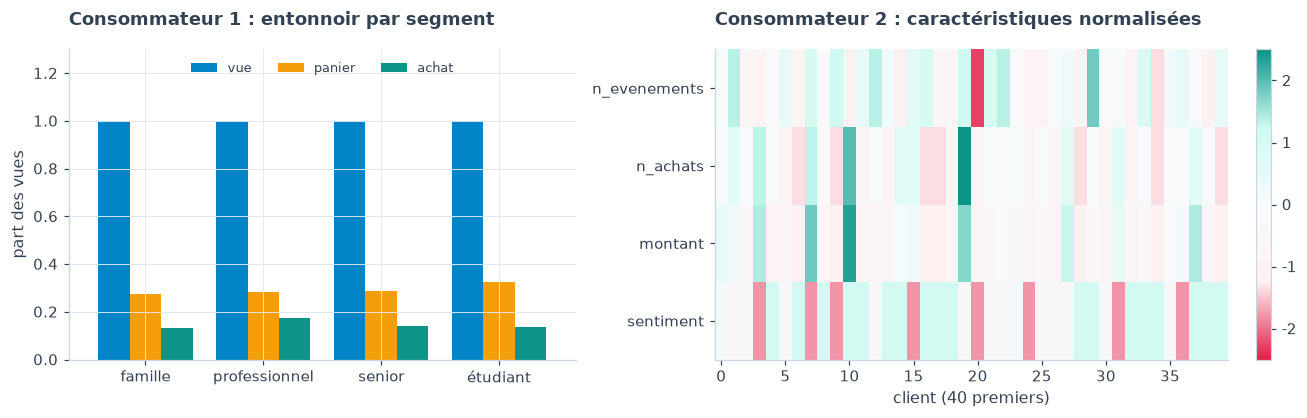

In [10]:
events = pd.concat([pd.read_json(p, lines=True) for p in sorted((lake / "events").glob("*.jsonl"))],
                   ignore_index=True)
seg = pd.read_csv(lake / "segments.csv")
print("colonnes découvertes à la lecture :", list(events.columns),
      f"; 'device' absent pour {events.device.isna().mean():.0%} des lignes")

# consommateur 1 : entonnoir de conversion par segment (vue analyste)
funnel = (events.merge(seg, on="user").groupby(["segment", "type"]).size().unstack()
          [["vue", "panier", "achat"]])
funnel = funnel.div(funnel["vue"], axis=0)

# consommateur 2 : matrice de caractéristiques (vue data scientist)
avis = pd.read_csv(lake / "avis.txt", sep="\t", names=["user", "texte"])
avis["sentiment"] = avis.texte.apply(lambda t: sum(w in POS_W for w in t.split()) - sum(w in NEG_W for w in t.split()))
feat = (events.groupby("user").agg(n_evenements=("type", "size"),
                                   n_achats=("type", lambda s: (s == "achat").sum()),
                                   montant=("amount", "sum"))
        .join(avis.groupby("user").sentiment.mean()).fillna(0))
X = ((feat - feat.mean()) / feat.std()).to_numpy()
print(f"matrice de caractéristiques : {X.shape[0]} clients x {X.shape[1]} colonnes")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1, 1.1]})
funnel.plot.bar(ax=axes[0], color=[SKY, AMBER, TEAL], rot=0, width=0.8)
axes[0].set_ylabel("part des vues"); axes[0].set_xlabel("")
axes[0].set_title("Consommateur 1 : entonnoir par segment"); axes[0].set_ylim(0, 1.3)
axes[0].legend(title=None, ncol=3, fontsize=8.5, loc="upper center")
im = axes[1].imshow(X[:40].T, aspect="auto", cmap="ddia_div", vmin=-2.5, vmax=2.5)
axes[1].set_yticks(range(X.shape[1])); axes[1].set_yticklabels(feat.columns); axes[1].grid(False)
axes[1].set_xlabel("client (40 premiers)")
axes[1].set_title("Consommateur 2 : caractéristiques normalisées")
plt.colorbar(im, ax=axes[1], fraction=0.03)
plt.tight_layout(); plt.show()

Les mêmes fichiers bruts servent deux usages que personne n'avait prévus au moment de
l'écriture ; le champ `device`, apparu le troisième jour, n'a cassé aucun des deux
(pandas le complète par des valeurs manquantes). Le revers de cette souplesse : sans
schéma imposé, rien n'empêche le lac de devenir un « marécage » de fichiers dont
personne ne connaît plus le sens. Les chaînes ETL se sont généralisées en **pipelines de
données**, et le lac sert souvent d'étape intermédiaire : sources, puis lac (données
brutes), puis entrepôt (données conformées).

> **À retenir.** Le lac de données stocke des fichiers bruts de tout format, sans schéma
> imposé, sur un stockage bon marché ; chaque consommateur applique son schéma à la
> lecture. Il sert notamment les data scientists, dont les transformations (matrices de
> caractéristiques, texte, images) s'expriment mal en SQL.

## 5. Au-delà du lac : flux d'événements et « reverse ETL » (section *Beyond the data lake*)

Trois évolutions récentes complètent le tableau. D'abord, la maturité des pratiques :
gouvernance, confidentialité et conformité (RGPD, CCPA) imposent de **gérer et opérer** les
pipelines analytiques avec rigueur (le « DataOps »). Ensuite, les données analytiques
arrivent de plus en plus sous forme de **flux d'événements** (chapitre 12) et
plus seulement de fichiers : là où une analyse de fichiers se relance périodiquement
(chaque jour), le traitement de flux réagit en quelques secondes, ce qui change tout
pour bloquer une fraude. Enfin, les résultats de l'analytique **reviennent** vers les
systèmes opérationnels (« reverse ETL ») : un modèle de recommandation entraîné dans le
système analytique est déployé en production pour servir les utilisateurs.

**Combien coûte une détection lente ?** Un fraudeur utilise une carte volée : il passe une
transaction de 80 euros en moyenne toutes les 10 minutes jusqu'à ce que la carte soit
bloquée. La détection elle-même est instantanée une fois l'analyse lancée ; seul compte
le délai avant que l'analyse ne voie les données.

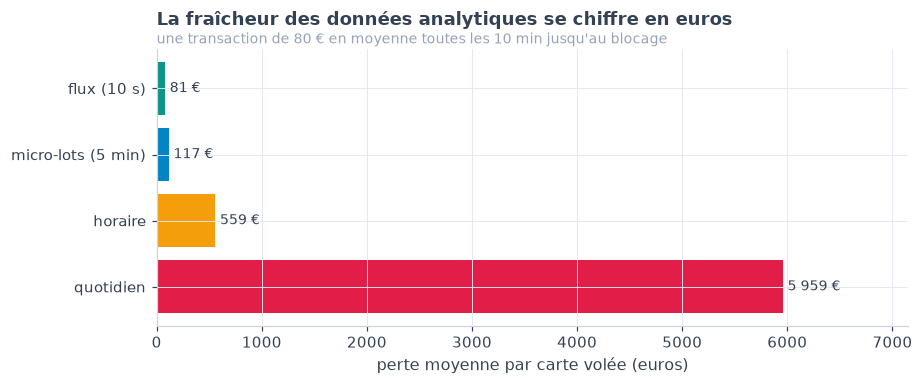

In [11]:
def fraud_loss(detect_delay_min, n_cards=2000, seed=1):
    r = np.random.default_rng(seed)
    losses = []
    for _ in range(n_cards):
        t, loss = 0.0, 0.0
        start = r.uniform(0, 1440)                                 # début de la fraude dans la journée
        if detect_delay_min >= 1440:                               # analyse quotidienne à minuit
            block_at = (1440 - start) + 5
        else:
            block_at = detect_delay_min
        while t < block_at:
            loss += r.exponential(80)
            t += r.exponential(10)
        losses.append(loss)
    return np.mean(losses)


delays = {"flux (10 s)": 10 / 60, "micro-lots (5 min)": 5, "horaire": 60, "quotidien": 1440}
loss = pd.Series({k: fraud_loss(v) for k, v in delays.items()})
fig, ax = plt.subplots(figsize=(8.5, 3.6))
b = ax.barh(loss.index[::-1], loss.values[::-1], color=[ROSE, AMBER, SKY, TEAL])
ax.bar_label(b, labels=[f"{v:,.0f} €".replace(",", " ") for v in loss.values[::-1]], padding=3, fontsize=9)
ax.set_xlim(0, loss.max() * 1.2)
ax.set_xlabel("perte moyenne par carte volée (euros)")
ax.set_title("La fraîcheur des données analytiques se chiffre en euros")
subtitle(ax, "une transaction de 80 € en moyenne toutes les 10 min jusqu'au blocage")
plt.tight_layout(); plt.show()

Avec une analyse quotidienne, le fraudeur a en moyenne une demi-journée devant lui ;
avec un traitement de flux, il passe au plus une transaction. Le schéma ci-dessous
résume la boucle complète : les données vont des systèmes opérationnels vers
l'analytique, et les résultats en reviennent.

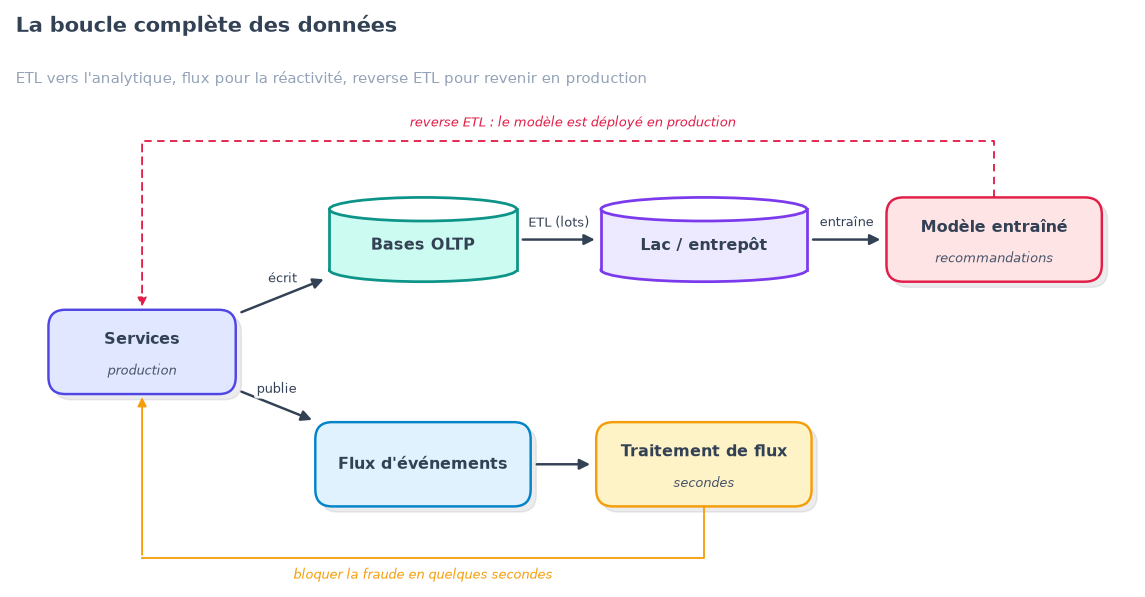

In [12]:
d = Diagram(12, 5.2, title="La boucle complète des données",
            subtitle="ETL vers l'analytique, flux pour la réactivité, reverse ETL pour revenir en production")
d.box("app", 1.4, 2.5, "Services", sub="production", color=INDIGO, w=2.0)
d.box("oltp", 4.4, 3.7, "Bases OLTP", color=TEAL, kind="db", w=2.0, h=0.9)
d.box("stream", 4.4, 1.3, "Flux d'événements", color=SKY, w=2.3)
d.box("lake", 7.4, 3.7, "Lac / entrepôt", color=VIOLET, kind="db", w=2.2, h=0.9)
d.box("sp", 7.4, 1.3, "Traitement de flux", sub="secondes", color=AMBER, w=2.3)
d.box("ml", 10.5, 3.7, "Modèle entraîné", sub="recommandations", color=ROSE, w=2.3)
d.arrow("app", "oltp", "écrit")
d.arrow("app", "stream", "publie")
d.arrow("oltp", "lake", "ETL (lots)")
d.arrow("stream", "sp")
d.arrow("lake", "ml", "entraîne")
d.line([(10.5, 4.15), (10.5, 4.75), (1.4, 4.75), (1.4, 2.95)], color=ROSE, style="dashed")
d.note(6.0, 4.95, "reverse ETL : le modèle est déployé en production", color=ROSE, fontsize=8.5)
d.line([(7.4, 0.85), (7.4, 0.3), (1.4, 0.3), (1.4, 2.05)], color=AMBER, style="solid")
d.note(4.4, 0.12, "bloquer la fraude en quelques secondes", color=AMBER, fontsize=8.5)
d.show()

> **À retenir.** L'analytique moderne ne se limite plus aux fichiers : les flux
> d'événements la rendent réactive (fraude, abus), et le reverse ETL renvoie ses résultats
> (modèles, scores, recommandations) vers les systèmes opérationnels.

## 6. Systèmes de référence et données dérivées (section *Systems of Record and Derived Data*)

Le livre distingue deux rôles qu'une donnée peut jouer :

- un **système de référence** (« system of record », ou source de vérité) détient la
  version **faisant autorité** : toute nouvelle donnée y est écrite d'abord, chaque fait y
  est représenté une seule fois (en général sous forme **normalisée**), et en cas de
  désaccord avec un autre système, c'est lui qui a raison, par définition ;
- un **système de données dérivées** contient le résultat d'une transformation de données
  venues d'ailleurs : si on le perd, on peut le **reconstruire** à partir de la source.
  Caches, index, vues matérialisées, valeurs dénormalisées, modèles entraînés en sont des
  exemples.

Les données dérivées sont **redondantes** (elles dupliquent une information existante),
mais souvent indispensables à la performance des lectures. Point important : ce n'est pas
l'outil qui décide du rôle, c'est l'usage qu'on en fait. La même base peut être source de
vérité dans une application et cache dans une autre.

Implémentons un système de référence minimal (des produits et des avis, normalisés) et
trois données dérivées : un **index inversé** pour la recherche par mot, une **vue
matérialisée** de la note moyenne par produit, et un **cache** des fiches produits
affichées.

In [13]:
class SystemOfRecord:
    def __init__(self):
        self.products = {}               # id -> nom
        self.reviews = {}                # id -> (produit, note, texte)

    def add_review(self, rid, pid, stars, text):
        self.reviews[rid] = (pid, stars, text)


def build_index(sor):                    # mot -> ensemble de produits
    idx = {}
    for pid, _, text in sor.reviews.values():
        for w in re.findall(r"\w+", text.lower()):
            idx.setdefault(w, set()).add(pid)
    return idx


def build_ratings(sor):                  # vue matérialisée : note moyenne par produit
    acc = {}
    for pid, stars, _ in sor.reviews.values():
        s, n = acc.get(pid, (0, 0)); acc[pid] = (s + stars, n + 1)
    return {pid: round(s / n, 2) for pid, (s, n) in acc.items()}


def build_cache(sor, ratings, hot):      # fiches des produits les plus consultés
    return {pid: {"nom": sor.products[pid], "note": ratings.get(pid)} for pid in hot}


sor = SystemOfRecord()
for p in range(50):
    sor.products[p] = f"produit {p}"
vocab = POS_W + NEG_W + ["solide", "joli", "bruyant", "léger"]
for r in range(500):
    sor.add_review(r, int(rng.integers(0, 50)), int(rng.integers(1, 6)), " ".join(rng.choice(vocab, 3)))

index, ratings = build_index(sor), build_ratings(sor)
cache = build_cache(sor, ratings, hot=range(10))
# on « perd » toutes les données dérivées, puis on les reconstruit depuis la source
index2, ratings2 = build_index(sor), build_ratings(sor)
cache2 = build_cache(sor, ratings2, hot=range(10))
print("reconstruction identique :", index == index2 and ratings == ratings2 and cache == cache2)

reconstruction identique : True


La reconstruction depuis la source redonne exactement les mêmes données dérivées : c'est
leur définition. Le vrai problème est ailleurs : **quand la source change, il faut
propager la modification** à toutes les données dérivées. Simulons des avis qui arrivent
un à un, avec une politique naïve : l'index et la vue sont mis à jour à chaque écriture,
mais le cache n'est reconstruit que toutes les 100 écritures. On mesure, après chaque
écriture, la part des fiches en cache dont la note diffère de la vérité.

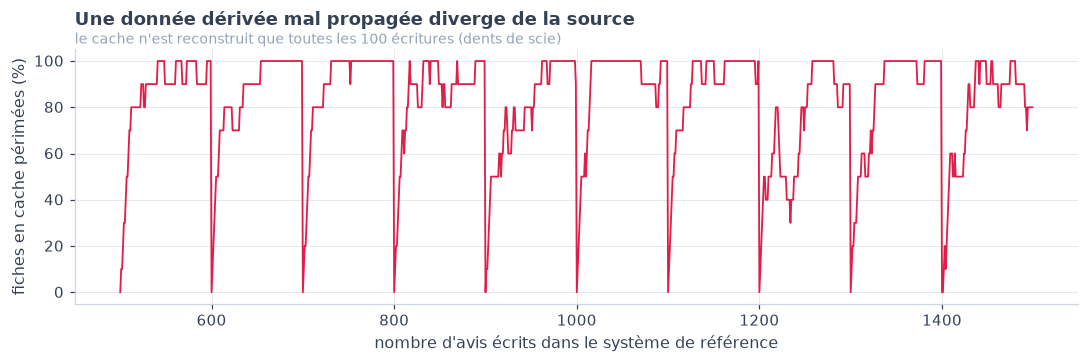

en moyenne, 83% des fiches en cache sont périmées


In [14]:
stale = []
for k in range(500, 1500):
    pid = int(rng.integers(0, 10))                                   # avis sur un produit populaire
    sor.add_review(k, pid, int(rng.integers(1, 6)), "nouvel avis")
    ratings = build_ratings(sor)                                     # propagé immédiatement
    if k % 100 == 0:
        cache = build_cache(sor, ratings, hot=range(10))             # propagé par lots
    stale.append(np.mean([cache[p]["note"] != ratings[p] for p in range(10)]))

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(np.arange(500, 1500), np.array(stale) * 100, color=ROSE, lw=1.2)
ax.set_xlabel("nombre d'avis écrits dans le système de référence")
ax.set_ylabel("fiches en cache périmées (%)")
ax.set_title("Une donnée dérivée mal propagée diverge de la source")
subtitle(ax, "le cache n'est reconstruit que toutes les 100 écritures (dents de scie)")
plt.tight_layout(); plt.show()
print(f"en moyenne, {np.mean(stale):.0%} des fiches en cache sont périmées")

Entre deux reconstructions, le cache diverge vite de la source : presque toutes les
fiches deviennent fausses en quelques dizaines d'écritures. Le livre note que la plupart
des bases supposent être seules au monde et facilitent peu cette propagation ; les
**pipelines de données** (chapitre 11) et les flux de modifications (chapitre
12) sont les outils pour la faire correctement.

**Le graphe de dérivation.** À l'échelle d'une organisation, rendre explicite « qui
dérive de qui » clarifie une architecture confuse. On le représente par un graphe orienté
(source vers dérivée) : quand une source change, ou quand il faut **effacer** une donnée
(cours 5), les descendants dans le graphe sont exactement ce qu'il faut recalculer, dans
un ordre topologique (fonction `ar.rebuild_order`).

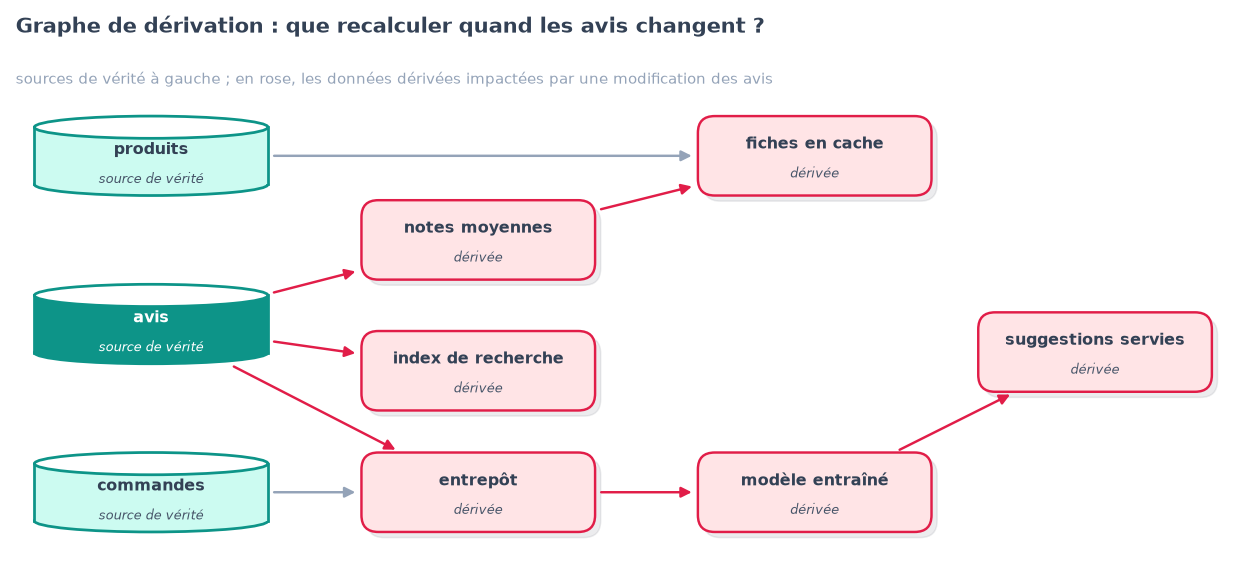

,ordre de recalcul
1,index de recherche
2,notes moyennes
3,entrepôt
4,fiches en cache
5,modèle entraîné
6,suggestions servies


In [15]:
G = nx.DiGraph([("avis (référence)", "index de recherche"), ("avis (référence)", "notes moyennes"),
                ("produits (référence)", "fiches en cache"), ("notes moyennes", "fiches en cache"),
                ("avis (référence)", "entrepôt"), ("commandes (référence)", "entrepôt"),
                ("entrepôt", "modèle entraîné"), ("modèle entraîné", "suggestions servies")])
pos_ = {"produits (référence)": (1.5, 4.4), "avis (référence)": (1.5, 2.6), "commandes (référence)": (1.5, 0.8),
        "notes moyennes": (5.0, 3.5), "index de recherche": (5.0, 2.1), "entrepôt": (5.0, 0.8),
        "fiches en cache": (8.6, 4.4), "modèle entraîné": (8.6, 0.8), "suggestions servies": (11.6, 2.3)}
impacted = set(ar.rebuild_order(G, "avis (référence)"))
d = Diagram(13.2, 5.0, title="Graphe de dérivation : que recalculer quand les avis changent ?",
            subtitle="sources de vérité à gauche ; en rose, les données dérivées impactées par une modification des avis")
for n, (x_, y_) in pos_.items():
    src = "référence" in n
    color = TEAL if src else (ROSE if n in impacted else GRAY)
    label = n.replace(" (référence)", "")
    d.box(n, x_, y_, label, sub="source de vérité" if src else "dérivée", color=color,
          kind="db" if src else "box", w=2.5, h=0.85, filled=(n == "avis (référence)"))
for a, b in G.edges:
    d.arrow(a, b, color=ROSE if (a in impacted or a == "avis (référence)") else GRAY)
d.show()
pd.DataFrame({"ordre de recalcul": ar.rebuild_order(G, "avis (référence)")}, index=range(1, 7))

L'ordre topologique garantit qu'on ne recalcule pas les fiches en cache avant les notes
moyennes dont elles dépendent, ni les suggestions avant le modèle. Les commandes et les
produits ne sont pas concernés.

> **À retenir.** Le système de référence détient la version qui fait autorité ; les
> données dérivées (caches, index, vues, modèles) se reconstruisent à partir de lui. Ce
> rôle dépend de l'usage, pas de l'outil. Le défi est de propager chaque modification de
> la source vers toutes ses dérivées : expliciter le graphe de dérivation dit quoi
> recalculer, et dans quel ordre.

## Synthèse

- Les systèmes OLTP forment des **silos** ; l'**entrepôt** en réunit une copie conformée,
  en lecture seule, dans un schéma en étoile. L'**ETL** transforme avant de charger,
  l'**ELT** charge le brut et transforme dans l'entrepôt, ce qui permet de recalculer.
- Un export périodique ne voit que des états ponctuels : à $\lambda T$ modifications par
  période, il capture une fraction $(1 - e^{-\lambda T})/\lambda T$ des versions. Les flux
  de modifications restituent l'historique.
- Le **HTAP** sert une application qui a besoin des deux mondes, sans remplacer
  l'entrepôt ; à grande échelle, les dispositions physiques s'opposent et les systèmes se
  spécialisent.
- Le **lac de données** stocke des fichiers bruts sans schéma imposé ; chaque
  consommateur applique le sien à la lecture. Flux d'événements et **reverse ETL**
  bouclent la boucle avec la production.
- **Système de référence** contre **données dérivées** : la seconde se reconstruit depuis
  la première, à condition de savoir propager les modifications ; le graphe de
  dérivation dit quoi recalculer.

Liens : schémas en étoile et modèles de données au chapitre 3 ; stockage
en colonnes au chapitre 4 ; formats de fichiers (Avro, Parquet) au chapitre
5 ; pipelines de traitement par lots au chapitre 11 ; capture de
changements et flux au chapitre 12. Le cours 3 passe au deuxième compromis du
chapitre : cloud ou auto-hébergement.